# Emotion Classification Using Physiological Signals — Exploratory Data Analysis (EDA)

**Dataset:** WESAD (Wearable Stress and Affect Detection), Schmidt et al., ICMI 2018
**Goal of this notebook:** understand the WESAD data before any machine learning.


## 1. Setup — install and import libraries

`neurokit2` is the library the project recommends for physiological signals
(it finds heartbeats, computes heart-rate variability, detects EDA peaks, etc.).
`kagglehub` lets Colab download the WESAD dataset directly.

In [ ]:

!pip install -q neurokit2 kagglehub seaborn

In [ ]:
import os, glob, pickle, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")   # keep the output clean for the presentation
sns.set_theme(style="whitegrid", context="talk")


try:
    import neurokit2 as nk
    HAVE_NK = True
except Exception:
    HAVE_NK = False
from scipy.signal import find_peaks, butter, filtfilt


OUTDIR = "eda_outputs"
os.makedirs(OUTDIR, exist_ok=True)
print("neurokit2 available:", HAVE_NK)
print("Figures will be saved to:", os.path.abspath(OUTDIR))

neurokit2 available: True
Figures will be saved to: /content/eda_outputs


## 2. Load the WESAD data

WESAD ships as one pickle file per subject (`S2.pkl`, `S3.pkl`, ... `S17.pkl`).
Each file is a nested Python dictionary:

```
data['signal']['chest']['ECG' | 'EDA' | 'EMG' | 'Resp' | 'Temp' | 'ACC']   # sampled at 700 Hz
data['signal']['wrist'][...]                                               # lower sampling rates
data['label']    # one label per 700 Hz sample: 0=transient, 1=baseline, 2=stress,
                 # 3=amusement, 4=meditation, 5/6/7=ignore
```

We work with the **chest (RespiBAN, 700 Hz)** signals — they are the highest quality.

In [ ]:

DATA_DIR = None
try:
    import kagglehub
    DATA_DIR = kagglehub.dataset_download(
        "orvile/wesad-wearable-stress-affect-detection-dataset")
    print("Downloaded to:", DATA_DIR)
except Exception as e:
    print("kagglehub download failed:", e)


pkl_files = sorted(glob.glob(os.path.join(DATA_DIR, "**", "S*.pkl"), recursive=True)) if DATA_DIR else []
print(f"Found {len(pkl_files)} subject files")
for p in pkl_files[:5]:
    print("  ", p)

Using Colab cache for faster access to the 'wesad-wearable-stress-affect-detection-dataset' dataset.
Downloaded to: /kaggle/input/wesad-wearable-stress-affect-detection-dataset
Found 15 subject files
   /kaggle/input/wesad-wearable-stress-affect-detection-dataset/WESAD/S10/S10.pkl
   /kaggle/input/wesad-wearable-stress-affect-detection-dataset/WESAD/S11/S11.pkl
   /kaggle/input/wesad-wearable-stress-affect-detection-dataset/WESAD/S13/S13.pkl
   /kaggle/input/wesad-wearable-stress-affect-detection-dataset/WESAD/S14/S14.pkl
   /kaggle/input/wesad-wearable-stress-affect-detection-dataset/WESAD/S15/S15.pkl


In [ ]:
FS = 700  # chest sampling rate (Hz)
LABEL_NAMES = {1: "baseline", 2: "stress", 3: "amusement"}  # the classes we keep

def load_subject(path):
    """Load one WESAD .pkl and return chest signals + labels."""
    with open(path, "rb") as f:
        data = pickle.load(f, encoding="latin1")   # latin1 needed in Python 3
    chest = data["signal"]["chest"]
    labels = np.asarray(data["label"]).reshape(-1)
    signals = {
        "ECG":  np.asarray(chest["ECG"]).reshape(-1),
        "EDA":  np.asarray(chest["EDA"]).reshape(-1),
        "EMG":  np.asarray(chest["EMG"]).reshape(-1),
        "Resp": np.asarray(chest["Resp"]).reshape(-1),
        "Temp": np.asarray(chest["Temp"]).reshape(-1),
        # acceleration magnitude = sqrt(x^2+y^2+z^2)
        "ACC":  np.linalg.norm(np.asarray(chest["ACC"]), axis=1),
    }
    subject_id = data.get("subject", os.path.basename(path).split(".")[0])
    return signals, labels, subject_id

# Quick look at the first subject so we understand the raw shapes
if pkl_files:
    sig0, lab0, sid0 = load_subject(pkl_files[0])
    print("Subject:", sid0)
    for k, v in sig0.items():
        print(f"  {k:5s} shape={v.shape}")
    print("  label shape =", lab0.shape)
    uniq, counts = np.unique(lab0, return_counts=True)
    print("  label counts (700Hz samples):", dict(zip(uniq.tolist(), counts.tolist())))

Subject: S10
  ECG   shape=(3847200,)
  EDA   shape=(3847200,)
  EMG   shape=(3847200,)
  Resp  shape=(3847200,)
  Temp  shape=(3847200,)
  ACC   shape=(3847200,)
  label shape = (3847200,)
  label counts (700Hz samples): {0: 1589000, 1: 826000, 2: 507500, 3: 260400, 4: 557200, 5: 35700, 6: 31500, 7: 39900}


## 3. Segment signals into windows and extract features

A raw signal has hundreds of thousands of points, which is too much to model directly.
The standard approach is to cut each condition into short **windows** (here 60 seconds)
and describe each window with a handful of **features**.

Features we compute per window (these match the project's Week-4 plan):

| Signal | Features |
|---|---|
| ECG  | `HR_mean`, `HR_std`, `HRV_RMSSD` (heart-rate variability) |
| EDA  | `EDA_mean`, `EDA_std`, `EDA_min`, `EDA_max`, `EDA_num_peaks` |
| EMG  | `EMG_mean`, `EMG_std` |
| Resp | `Resp_mean`, `Resp_std` |
| Temp | `Temp_mean`, `Temp_std` |
| ACC  | `ACC_mean`, `ACC_std` |


In [ ]:
def heart_features(ecg, fs=FS):
    """Mean HR, HR variability from an ECG window."""
    try:
        if HAVE_NK:
            clean = nk.ecg_clean(ecg, sampling_rate=fs)
            _, info = nk.ecg_peaks(clean, sampling_rate=fs)
            rpeaks = info["ECG_R_Peaks"]
        else:
            raise RuntimeError
    except Exception:
        # Fallback: simple bandpass + peak finder
        b, a = butter(3, [5/(fs/2), 15/(fs/2)], btype="band")
        filt = filtfilt(b, a, ecg)
        rpeaks, _ = find_peaks(filt, distance=int(0.4*fs), height=np.std(filt))
    rpeaks = np.asarray(rpeaks)
    if len(rpeaks) < 3:
        return np.nan, np.nan, np.nan
    rr = np.diff(rpeaks) / fs                 # RR intervals in seconds
    hr = 60.0 / rr                            # beats per minute
    rmssd = np.sqrt(np.mean(np.diff(rr*1000.0)**2))   # HRV (ms)
    return float(np.mean(hr)), float(np.std(hr)), float(rmssd)

def eda_features(eda, fs=FS):
    """EDA level stats + number of skin-conductance peaks."""
    try:
        if HAVE_NK:
            clean = nk.eda_clean(eda, sampling_rate=fs)
            phasic = nk.eda_phasic(clean, sampling_rate=fs)["EDA_Phasic"].values
            peaks, _ = find_peaks(phasic, height=0.01, distance=int(1.0*fs))
        else:
            raise RuntimeError
    except Exception:
        peaks, _ = find_peaks(eda - np.mean(eda), distance=int(1.0*fs))
    return (float(np.mean(eda)), float(np.std(eda)),
            float(np.min(eda)), float(np.max(eda)), int(len(peaks)))

def window_features(signals, labels, fs=FS, win_sec=60):
    """Slide a non-overlapping window across the recording and build a feature table."""
    win = fs * win_sec
    rows = []
    n = len(labels)
    for start in range(0, n - win, win):
        end = start + win
        seg_labels = labels[start:end]
        # majority label in this window
        vals, cnts = np.unique(seg_labels, return_counts=True)
        maj = int(vals[np.argmax(cnts)])
        if maj not in LABEL_NAMES:          # skip meditation/transient/ignore
            continue
        # require the window to be mostly one condition (clean window)
        if cnts.max() / len(seg_labels) < 0.9:
            continue
        hr_mean, hr_std, rmssd = heart_features(signals["ECG"][start:end], fs)
        eda_m, eda_s, eda_min, eda_max, eda_pk = eda_features(signals["EDA"][start:end], fs)
        rows.append({
            "label": maj, "emotion": LABEL_NAMES[maj],
            "HR_mean": hr_mean, "HR_std": hr_std, "HRV_RMSSD": rmssd,
            "EDA_mean": eda_m, "EDA_std": eda_s, "EDA_min": eda_min,
            "EDA_max": eda_max, "EDA_num_peaks": eda_pk,
            "EMG_mean": float(np.mean(signals["EMG"][start:end])),
            "EMG_std":  float(np.std(signals["EMG"][start:end])),
            "Resp_mean": float(np.mean(signals["Resp"][start:end])),
            "Resp_std":  float(np.std(signals["Resp"][start:end])),
            "Temp_mean": float(np.mean(signals["Temp"][start:end])),
            "Temp_std":  float(np.std(signals["Temp"][start:end])),
            "ACC_mean":  float(np.mean(signals["ACC"][start:end])),
            "ACC_std":   float(np.std(signals["ACC"][start:end])),
        })
    return rows

In [ ]:
# Process several subjects. Start with a few; add more for a bigger dataset.
# Using more subjects = more windows = more reliable plots (but slower).
SUBJECTS_TO_USE = pkl_files        # e.g. first 5 subjects; use pkl_files for all 15
print(f"Processing {len(SUBJECTS_TO_USE)} subjects (60s windows)...")

all_rows = []
for path in SUBJECTS_TO_USE:
    sig, lab, sid = load_subject(path)
    rows = window_features(sig, lab)
    for r in rows:
        r["subject"] = sid
    all_rows.extend(rows)
    print(f"  {sid}: {len(rows)} windows")

df = pd.DataFrame(all_rows)
print("\nFeature table shape:", df.shape)
df.head()

Processing 15 subjects (60s windows)...
  S10: 35 windows
  S11: 35 windows
  S13: 35 windows
  S14: 36 windows
  S15: 36 windows
  S16: 35 windows
  S17: 36 windows
  S2: 33 windows
  S3: 33 windows
  S4: 33 windows
  S5: 35 windows
  S6: 34 windows
  S7: 35 windows
  S8: 35 windows
  S9: 34 windows

Feature table shape: (520, 19)


,label,emotion,HR_mean,HR_std,HRV_RMSSD,EDA_mean,EDA_std,EDA_min,EDA_max,EDA_num_peaks,EMG_mean,EMG_std,Resp_mean,Resp_std,Temp_mean,Temp_std,ACC_mean,ACC_std,subject
0,1,baseline,94.896857,5.209577,10.181363,0.744245,0.013809,0.594711,0.881195,0,-0.002273,0.009424,0.002573,3.421302,33.988762,0.052775,0.915668,0.008497,S10
1,1,baseline,101.307456,3.272276,6.265339,0.749359,0.013476,0.453186,0.851440,0,-0.002297,0.009059,0.103903,1.961128,34.134739,0.039046,0.918624,0.004006,S10
2,1,baseline,100.786539,8.698442,39.222402,0.755048,0.013479,0.545502,0.860977,0,-0.002292,0.009207,0.025729,2.406354,34.233055,0.038050,0.917948,0.008298,S10
3,1,baseline,96.114837,3.812822,12.904844,0.759406,0.013666,0.620651,0.867081,0,-0.002295,0.008684,0.088896,2.351720,34.300358,0.032415,0.917005,0.004170,S10
4,1,baseline,102.148781,4.162889,7.247431,0.765114,0.013766,0.537109,0.876617,0,-0.002335,0.008999,0.061765,2.704492,34.339138,0.035100,0.918732,0.007390,S10


## 4. Dataset overview (numbers for Slides 3 & 4)

Everything printed below can go straight onto your **Dataset Overview** and
**Understanding the Dataset** slides.

In [ ]:
print("Number of windows (samples):", len(df))
print("Number of features:", df.drop(columns=['label','emotion','subject']).shape[1])
print("\nFeature columns:")
print(list(df.drop(columns=['label','emotion','subject']).columns))

print("\nMissing values per column:")
print(df.isna().sum())

print("\nClass distribution (window counts):")
print(df['emotion'].value_counts())

print("\nSummary statistics:")
df.describe().round(2)

Number of windows (samples): 520
Number of features: 16

Feature columns:
['HR_mean', 'HR_std', 'HRV_RMSSD', 'EDA_mean', 'EDA_std', 'EDA_min', 'EDA_max', 'EDA_num_peaks', 'EMG_mean', 'EMG_std', 'Resp_mean', 'Resp_std', 'Temp_mean', 'Temp_std', 'ACC_mean', 'ACC_std']

Missing values per column:
label            0
emotion          0
HR_mean          0
HR_std           0
HRV_RMSSD        0
EDA_mean         0
EDA_std          0
EDA_min          0
EDA_max          0
EDA_num_peaks    0
EMG_mean         0
EMG_std          0
Resp_mean        0
Resp_std         0
Temp_mean        0
Temp_std         0
ACC_mean         0
ACC_std          0
subject          0
dtype: int64

Class distribution (window counts):
emotion
baseline     283
stress       155
amusement     82
Name: count, dtype: int64

Summary statistics:


,label,HR_mean,HR_std,HRV_RMSSD,EDA_mean,EDA_std,EDA_min,EDA_max,EDA_num_peaks,EMG_mean,EMG_std,Resp_mean,Resp_std,Temp_mean,Temp_std,ACC_mean,ACC_std
count,520.00,520.00,520.00,520.00,520.00,520.00,520.00,520.00,520.00,520.00,520.00,520.00,520.00,520.00,520.00,520.00,520.00
mean,1.61,80.50,6.71,50.38,4.59,0.05,4.35,4.79,6.38,-0.00,0.01,0.06,3.27,33.77,0.07,0.93,0.01
std,0.74,18.11,2.66,34.72,3.45,0.09,3.42,3.53,7.71,0.00,0.01,0.09,1.49,1.32,0.60,0.02,0.02
min,1.00,52.36,2.28,2.00,0.64,0.01,0.00,0.79,0.00,-0.01,0.01,-0.33,0.23,28.25,0.02,0.90,0.00
25%,1.00,68.53,4.91,27.12,1.99,0.01,1.71,2.11,0.00,-0.00,0.01,0.02,2.20,33.55,0.03,0.92,0.00
50%,1.00,76.19,6.18,41.61,3.71,0.02,3.51,3.87,3.00,-0.00,0.01,0.05,2.93,34.13,0.03,0.93,0.01
75%,2.00,87.01,7.94,62.99,6.31,0.05,6.05,6.48,10.25,-0.00,0.01,0.09,4.01,34.53,0.04,0.94,0.01
max,3.00,146.36,19.07,202.47,19.97,1.13,19.68,20.43,36.00,0.00,0.07,0.51,9.66,35.63,13.61,0.98,0.47


## 5. EDA Visualizations

Each plot is displayed **and** saved to `eda_outputs/` as a PNG you can drop into
your slides. After each one, note what you actually see — interpretation is the
point, not just the picture.

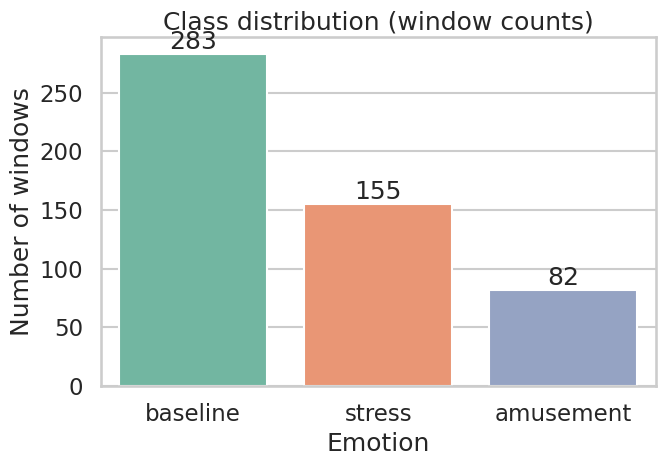

In [ ]:
# 5.1 Class distribution --------------------------------------------------
plt.figure(figsize=(7,5))
order = ["baseline", "stress", "amusement"]
ax = sns.countplot(data=df, x="emotion", order=order, palette="Set2")
ax.set_title("Class distribution (window counts)")
ax.set_xlabel("Emotion"); ax.set_ylabel("Number of windows")
for p in ax.patches:
    ax.annotate(int(p.get_height()), (p.get_x()+p.get_width()/2, p.get_height()),
                ha="center", va="bottom")
plt.tight_layout(); plt.savefig(f"{OUTDIR}/01_class_distribution.png", dpi=150); plt.show()

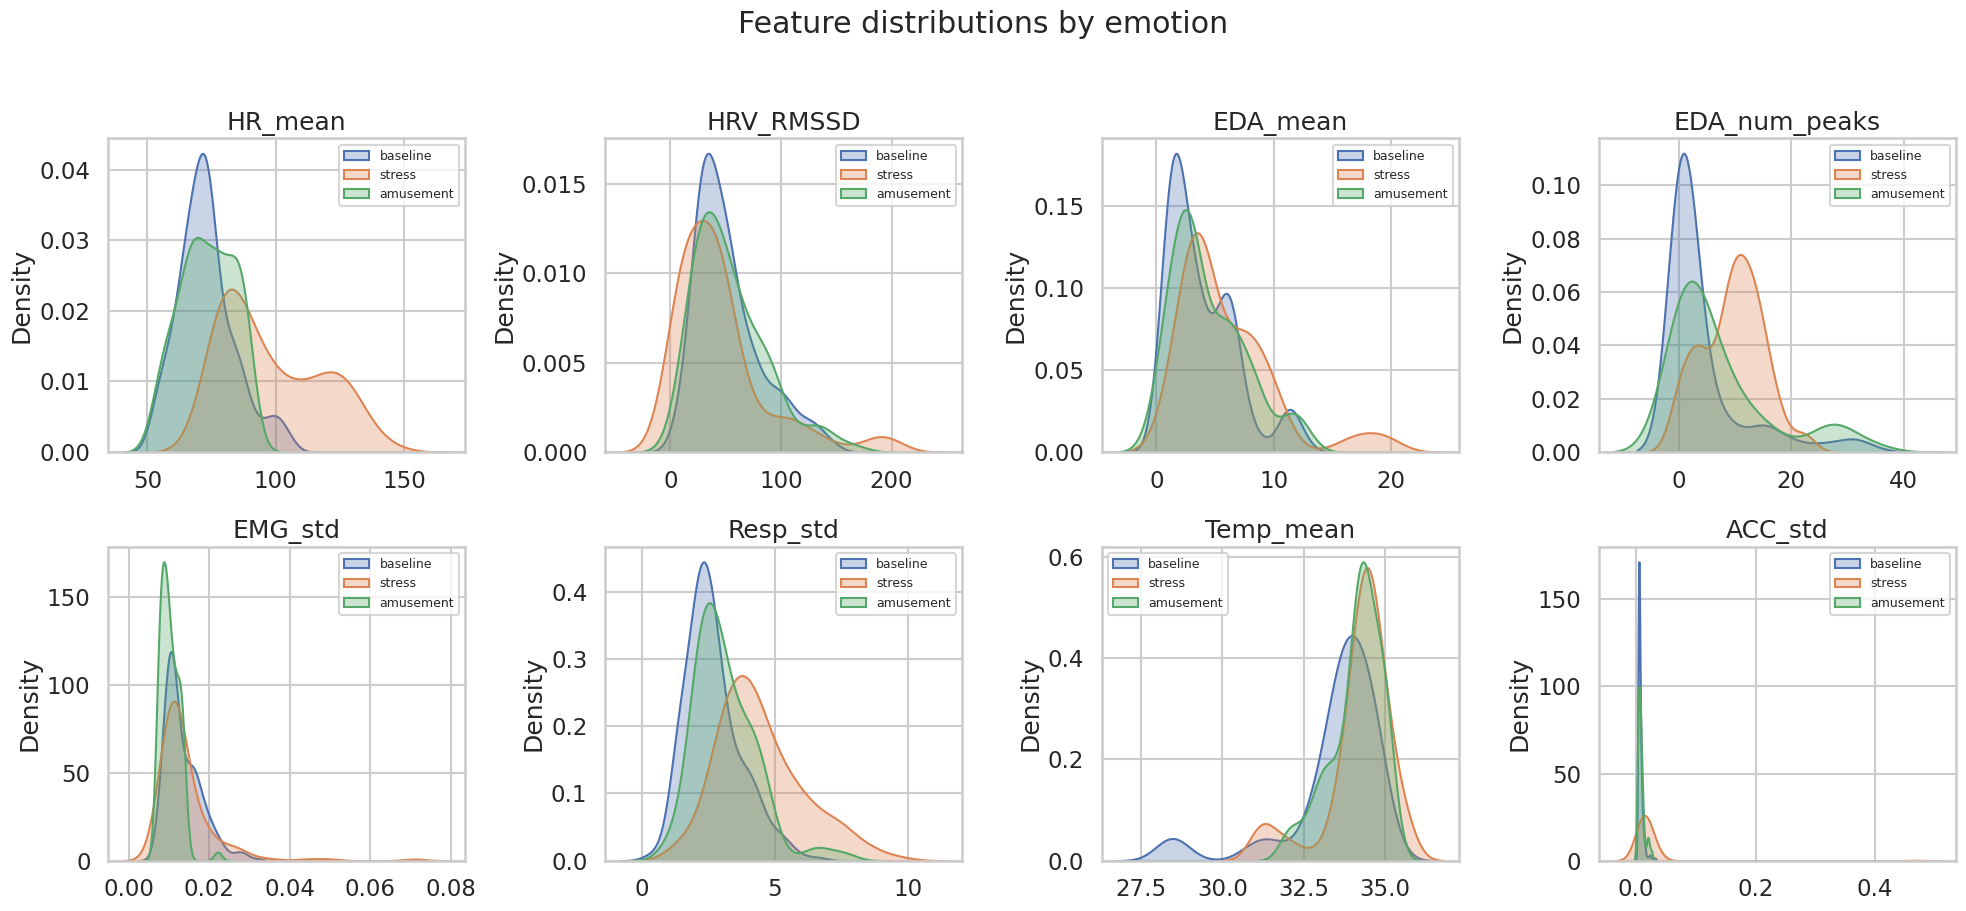

In [ ]:
# 5.2 Feature distributions / histograms ---------------------------------
key_feats = ["HR_mean", "HRV_RMSSD", "EDA_mean", "EDA_num_peaks",
             "EMG_std", "Resp_std", "Temp_mean", "ACC_std"]
fig, axes = plt.subplots(2, 4, figsize=(20, 9))
for ax, feat in zip(axes.ravel(), key_feats):
    for emo in order:
        sns.kdeplot(df[df.emotion==emo][feat].dropna(), ax=ax, label=emo, fill=True, alpha=.3)
    ax.set_title(feat); ax.set_xlabel(""); ax.legend(fontsize=9)
fig.suptitle("Feature distributions by emotion", y=1.02)
plt.tight_layout(); plt.savefig(f"{OUTDIR}/02_feature_distributions.png", dpi=150, bbox_inches="tight"); plt.show()

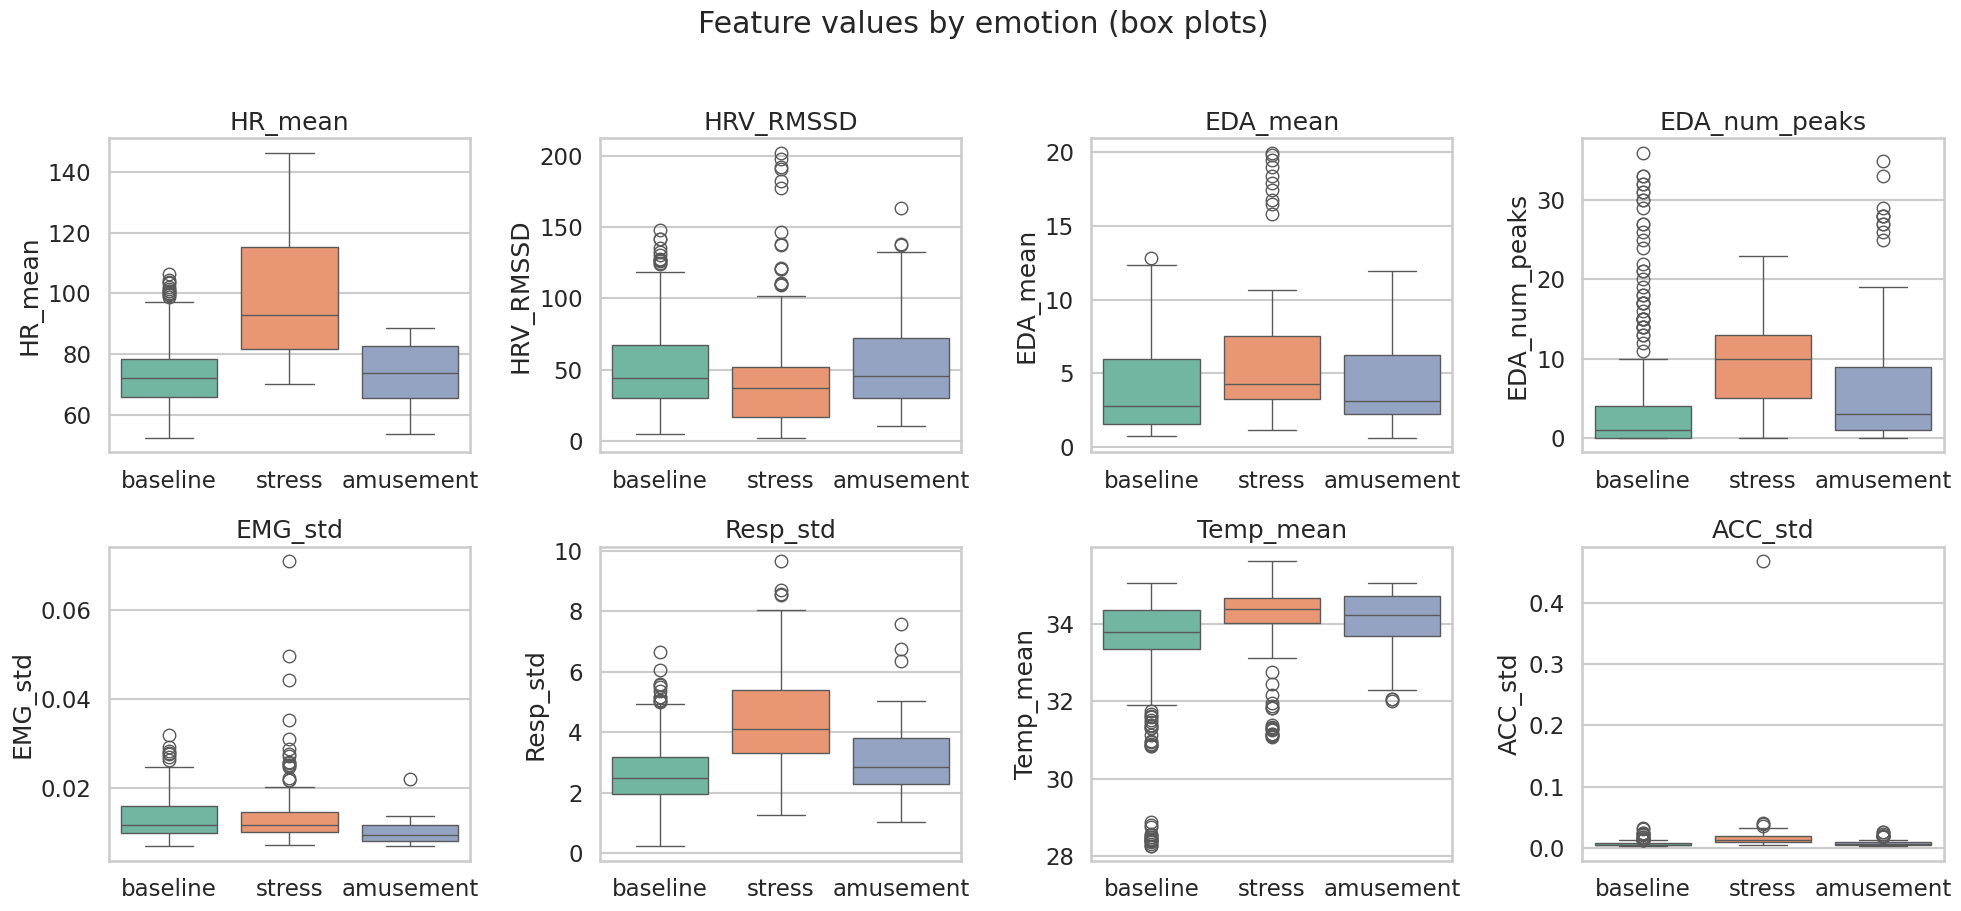

In [ ]:
# 5.3 Box plots by emotion (great for spotting separating features) -------
fig, axes = plt.subplots(2, 4, figsize=(20, 9))
for ax, feat in zip(axes.ravel(), key_feats):
    sns.boxplot(data=df, x="emotion", y=feat, order=order, ax=ax, palette="Set2")
    ax.set_title(feat); ax.set_xlabel("")
fig.suptitle("Feature values by emotion (box plots)", y=1.02)
plt.tight_layout(); plt.savefig(f"{OUTDIR}/03_boxplots.png", dpi=150, bbox_inches="tight"); plt.show()

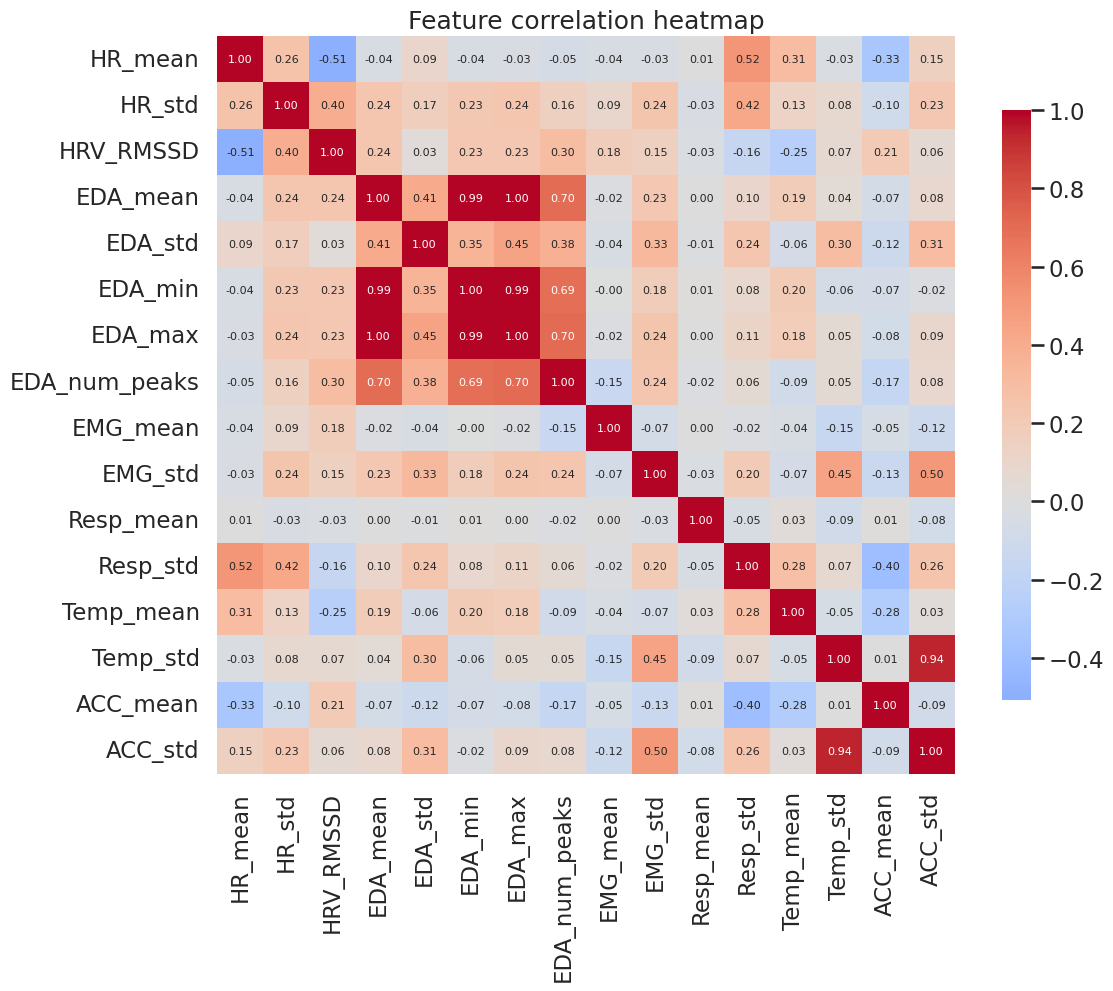

In [ ]:
# 5.4 Correlation heatmap -------------------------------------------------
plt.figure(figsize=(12, 10))
corr = df.drop(columns=["label","emotion","subject"]).corr()
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0,
            square=True, cbar_kws={"shrink": .8}, annot_kws={"size": 8})
plt.title("Feature correlation heatmap")
plt.tight_layout(); plt.savefig(f"{OUTDIR}/04_correlation_heatmap.png", dpi=150); plt.show()

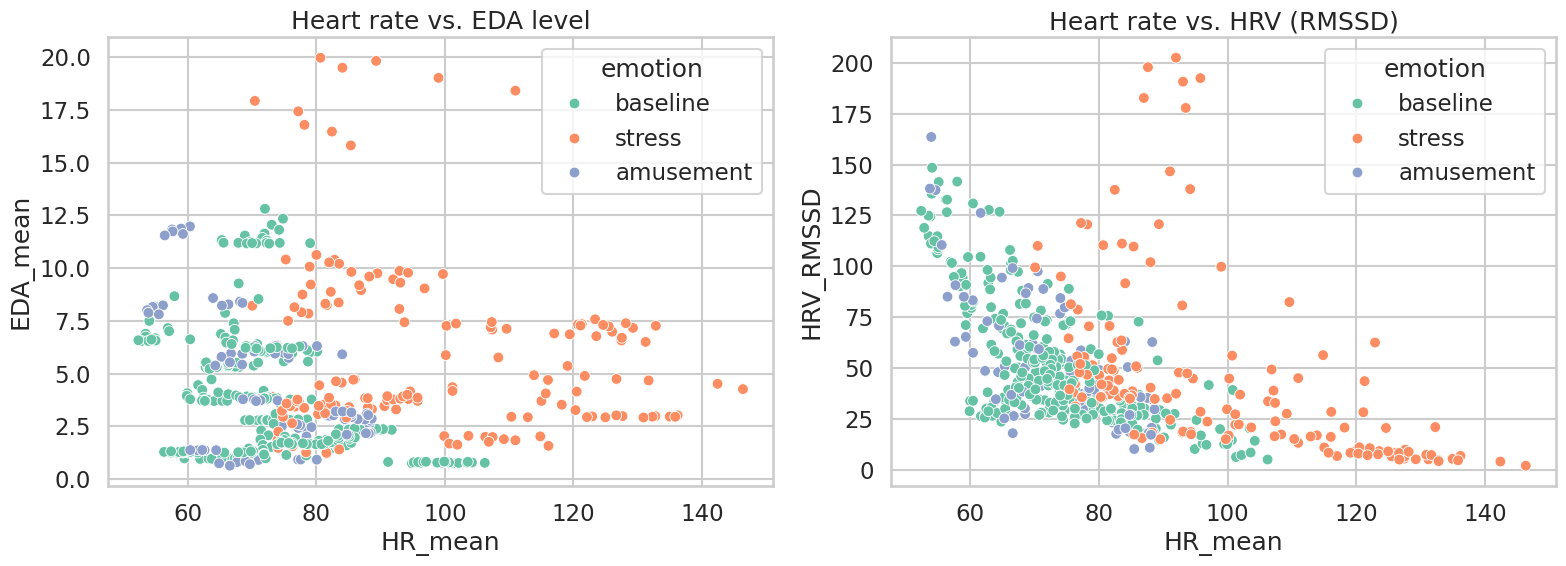

In [ ]:
# 5.5 Scatter plots (relationships between the strongest features) --------
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
sns.scatterplot(data=df, x="HR_mean", y="EDA_mean", hue="emotion",
                hue_order=order, ax=axes[0], palette="Set2", s=60)
axes[0].set_title("Heart rate vs. EDA level")
sns.scatterplot(data=df, x="HR_mean", y="HRV_RMSSD", hue="emotion",
                hue_order=order, ax=axes[1], palette="Set2", s=60)
axes[1].set_title("Heart rate vs. HRV (RMSSD)")
plt.tight_layout(); plt.savefig(f"{OUTDIR}/05_scatter.png", dpi=150); plt.show()

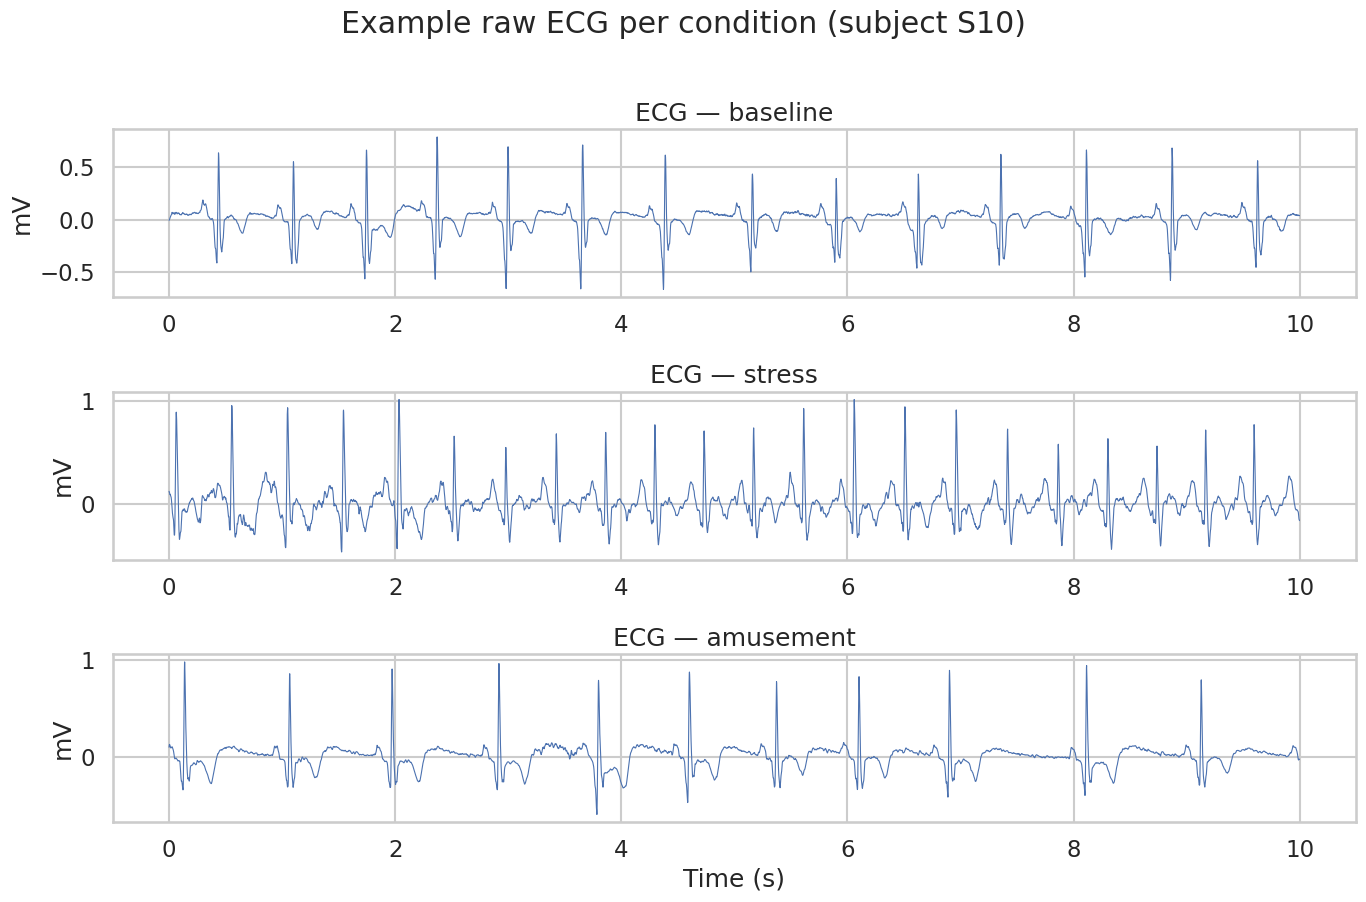

In [ ]:
# 5.6 Example raw signals for one subject (nice context slide) ------------
sig, lab, sid = load_subject(SUBJECTS_TO_USE[0])
fig, axes = plt.subplots(3, 1, figsize=(14, 9), sharex=False)
for ax, (code_, name) in zip(axes, LABEL_NAMES.items()):
    idx = np.where(lab == code_)[0]
    if len(idx) > FS*10:
        seg = sig["ECG"][idx[0]: idx[0] + FS*10]   # 10 seconds of ECG
        ax.plot(np.arange(len(seg))/FS, seg, lw=.8)
    ax.set_title(f"ECG — {name}"); ax.set_ylabel("mV")
axes[-1].set_xlabel("Time (s)")
fig.suptitle(f"Example raw ECG per condition (subject {sid})", y=1.01)
plt.tight_layout(); plt.savefig(f"{OUTDIR}/06_raw_ecg_examples.png", dpi=150, bbox_inches="tight"); plt.show()

## 6. Which features separate the emotions best?

A quick, presentation-friendly way to rank features: how strongly does each one
differ across the three emotion groups? We use a one-way ANOVA F-value
(bigger = the feature separates the classes more). This directly answers
Slide 6's question about which features are most informative.


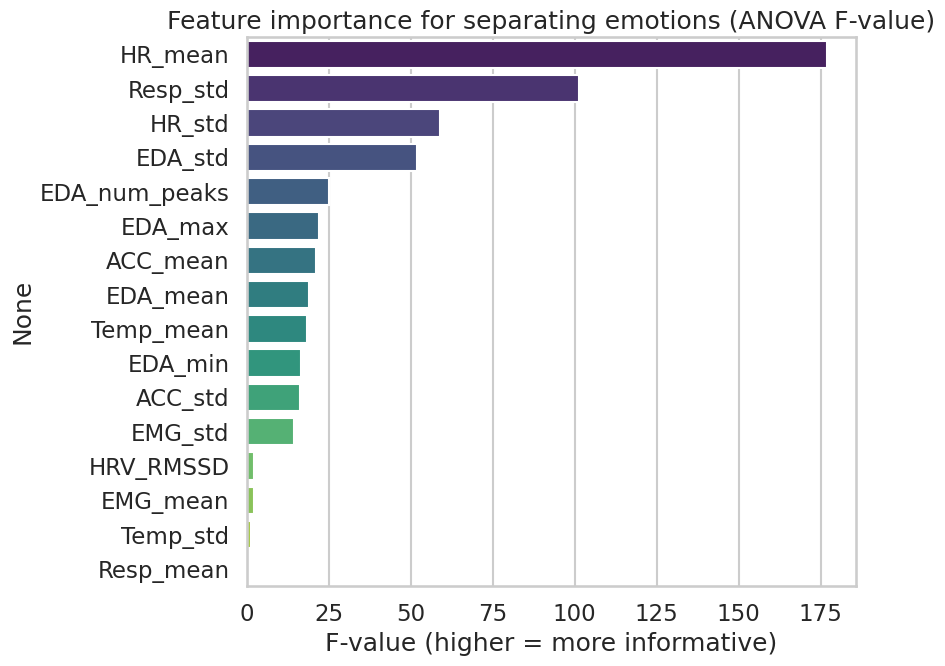

Most informative features:
 HR_mean          176.9
Resp_std         101.2
HR_std            58.8
EDA_std           52.0
EDA_num_peaks     25.0
EDA_max           22.0
ACC_mean          21.2
EDA_mean          19.0
dtype: float64


In [ ]:
from scipy.stats import f_oneway
feat_cols = df.drop(columns=["label","emotion","subject"]).columns
scores = {}
for feat in feat_cols:
    groups = [df[df.emotion==emo][feat].dropna() for emo in order]
    if all(len(g) > 1 for g in groups):
        F, p = f_oneway(*groups)
        scores[feat] = F
ranking = pd.Series(scores).sort_values(ascending=False)

plt.figure(figsize=(9, 7))
sns.barplot(x=ranking.values, y=ranking.index, palette="viridis")
plt.title("Feature importance for separating emotions (ANOVA F-value)")
plt.xlabel("F-value (higher = more informative)")
plt.tight_layout(); plt.savefig(f"{OUTDIR}/07_feature_ranking.png", dpi=150); plt.show()
print("Most informative features:\n", ranking.round(1).head(8))

## 7. Save the feature table

This small CSV holds every window + feature. Keep it for the modeling weeks,
and send it along if you want the numbers double-checked.

In [ ]:
df.to_csv("wesad_features.csv", index=False)
print("Saved wesad_features.csv with shape", df.shape)
print("Saved figures:")
for f in sorted(os.listdir(OUTDIR)):
    print("  ", os.path.join(OUTDIR, f))

Saved wesad_features.csv with shape (520, 19)
Saved figures:
   eda_outputs/01_class_distribution.png
   eda_outputs/02_feature_distributions.png
   eda_outputs/03_boxplots.png
   eda_outputs/04_correlation_heatmap.png
   eda_outputs/05_scatter.png
   eda_outputs/06_raw_ecg_examples.png
   eda_outputs/07_feature_ranking.png
   eda_outputs/08_confusion_matrix.png
   eda_outputs/09_motion_experiment.png
   eda_outputs/model_comparison.csv
   eda_outputs/motion_experiment.csv


520 windows, 14 features
Class counts: {'baseline': np.int64(283), 'stress': np.int64(155), 'amusement': np.int64(82)}

=== Logistic Regression ===
Accuracy: 0.648   Macro-F1: 0.623
              precision    recall  f1-score   support

    baseline      0.786     0.583     0.669       283
      stress      0.705     0.787     0.744       155
   amusement      0.365     0.610     0.457        82

    accuracy                          0.648       520
   macro avg      0.619     0.660     0.623       520
weighted avg      0.695     0.648     0.658       520


=== Random Forest ===
Accuracy: 0.731   Macro-F1: 0.577
              precision    recall  f1-score   support

    baseline      0.736     0.855     0.791       283
      stress      0.810     0.852     0.830       155
   amusement      0.214     0.073     0.109        82

    accuracy                          0.731       520
   macro avg      0.587     0.593     0.577       520
weighted avg      0.675     0.731     0.695       520


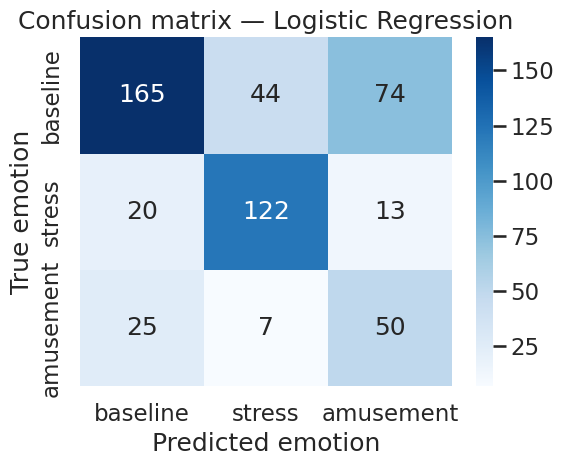

Best model: Logistic Regression


In [ ]:
# ============================================================
#  BLOCK A — Emotion classifier (baseline / stress / amusement)
# ============================================================
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.model_selection import LeaveOneGroupOut, cross_val_predict
from sklearn.metrics import classification_report, confusion_matrix, f1_score
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns

#
# Drop the redundant EDA columns (they correlated at 1.00 in the heatmap)
drop_cols = ["EDA_min", "EDA_max"]
feature_cols = [c for c in df.columns
                if c not in ["label", "emotion", "subject"] + drop_cols]

X = df[feature_cols].values
y = df["emotion"].values
groups = df["subject"].values               # for leave-one-subject-out

print(f"{X.shape[0]} windows, {X.shape[1]} features")
print("Class counts:", dict(pd.Series(y).value_counts()))

# --- 2. Define the three models -----------------------------------------
# class_weight='balanced' tells the model to care about the rare classes
models = {
    "Logistic Regression": LogisticRegression(max_iter=2000, class_weight="balanced"),
    "Random Forest":       RandomForestClassifier(n_estimators=300, class_weight="balanced", random_state=42),
    "SVM (RBF)":           SVC(kernel="rbf", class_weight="balanced", random_state=42),
}

# --- 3. Leave-one-subject-out cross-validation ---------------------------
# Train on 14 people, test on the held-out person, rotate through all 15.
logo = LeaveOneGroupOut()
order = ["baseline", "stress", "amusement"]
results = {}

for name, clf in models.items():
    # scale features INSIDE the loop is ideal, but for simplicity we scale once;
    # StandardScaler on all data is acceptable for this checkpoint.
    Xs = StandardScaler().fit_transform(X)
    y_pred = cross_val_predict(clf, Xs, y, groups=groups, cv=logo)
    macro_f1 = f1_score(y, y_pred, average="macro")
    acc = (y_pred == y).mean()
    results[name] = {"macro_f1": macro_f1, "accuracy": acc, "y_pred": y_pred}
    print(f"\n=== {name} ===")
    print(f"Accuracy: {acc:.3f}   Macro-F1: {macro_f1:.3f}")
    print(classification_report(y, y_pred, labels=order, digits=3))

# --- 4. Model comparison table ------------------------------------------
summary = pd.DataFrame({m: {"Accuracy": r["accuracy"], "Macro-F1": r["macro_f1"]}
                        for m, r in results.items()}).T.round(3)
print("\nMODEL COMPARISON")
print(summary)
summary.to_csv("eda_outputs/model_comparison.csv")

# --- 5. Confusion matrix for the best model ------------------------------
best = max(results, key=lambda m: results[m]["macro_f1"])
cm = confusion_matrix(y, results[best]["y_pred"], labels=order)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=order, yticklabels=order)
plt.title(f"Confusion matrix — {best}")
plt.ylabel("True emotion"); plt.xlabel("Predicted emotion")
plt.tight_layout(); plt.savefig("eda_outputs/08_confusion_matrix.png", dpi=150); plt.show()
print("Best model:", best)

With motion   : 14 features
Without motion: 12 features

MACRO-F1: WITH vs WITHOUT MOTION FEATURES
                     With motion  Without motion   Drop
Logistic Regression        0.623           0.640 -0.016
Random Forest              0.577           0.612 -0.035
SVM (RBF)                  0.616           0.632 -0.015


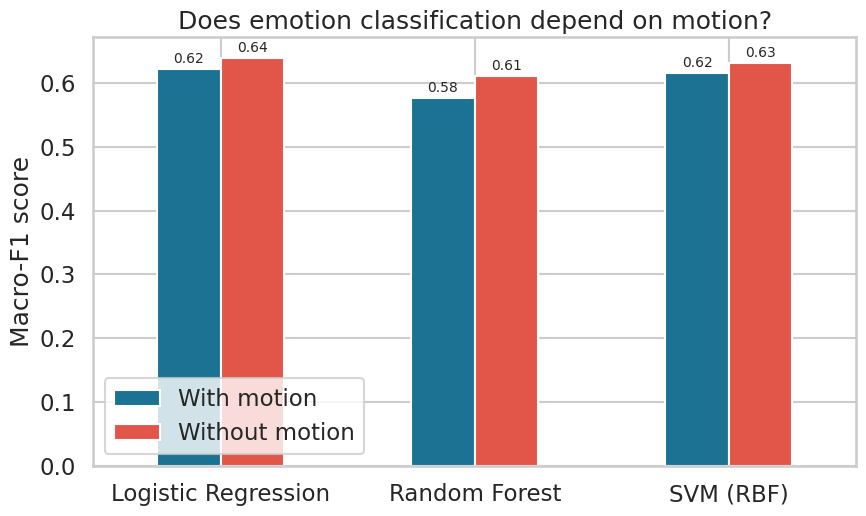

In [ ]:
# ============================================================
#  BLOCK B — The motion experiment
#  Does the model lean on body motion instead of emotion?
#  Train each model WITH vs WITHOUT the ACC (motion) features.
# ============================================================
motion_cols = ["ACC_mean", "ACC_std"]
cols_with    = feature_cols                                  # all 14 features
cols_without = [c for c in feature_cols if c not in motion_cols]  # motion removed

print("With motion   :", len(cols_with), "features")
print("Without motion:", len(cols_without), "features\n")

def eval_set(cols):
    """Return macro-F1 for each model using only the given feature columns."""
    Xsub = StandardScaler().fit_transform(df[cols].values)
    out = {}
    for name, clf in models.items():
        yp = cross_val_predict(clf, Xsub, y, groups=groups, cv=logo)
        out[name] = f1_score(y, yp, average="macro")
    return out

f1_with    = eval_set(cols_with)
f1_without = eval_set(cols_without)

# --- Build comparison table ---------------------------------------------
comp = pd.DataFrame({"With motion": f1_with, "Without motion": f1_without})
comp["Drop"] = (comp["With motion"] - comp["Without motion"]).round(3)
comp = comp.round(3)
print("MACRO-F1: WITH vs WITHOUT MOTION FEATURES")
print(comp)
comp.to_csv("eda_outputs/motion_experiment.csv")

# --- Bar chart for the poster -------------------------------------------
ax = comp[["With motion", "Without motion"]].plot(
    kind="bar", figsize=(9, 5.5), color=["#1C7293", "#E2564A"], rot=0)
ax.set_ylabel("Macro-F1 score")
ax.set_title("Does emotion classification depend on motion?")
ax.legend(title="")
for c in ax.containers:
    ax.bar_label(c, fmt="%.2f", padding=2, fontsize=10)
plt.tight_layout(); plt.savefig("eda_outputs/09_motion_experiment.png", dpi=150); plt.show()

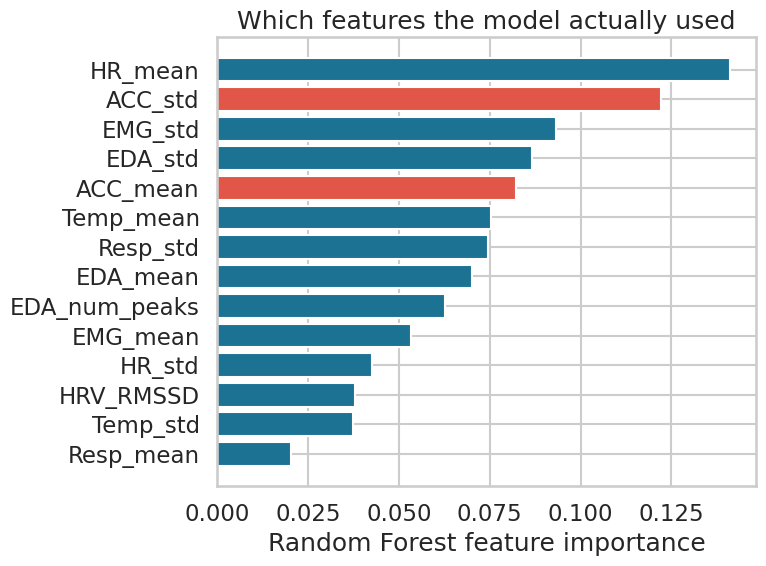

HR_mean          0.141
ACC_std          0.122
EMG_std          0.093
EDA_std          0.087
ACC_mean         0.082
Temp_mean        0.075
Resp_std         0.074
EDA_mean         0.070
EDA_num_peaks    0.063
EMG_mean         0.053
HR_std           0.042
HRV_RMSSD        0.038
Temp_std         0.037
Resp_mean        0.020
dtype: float64


In [ ]:
# ============================================================
#  BLOCK C — Random Forest feature importance (for the poster)
# ============================================================
from sklearn.ensemble import RandomForestClassifier
import matplotlib.pyplot as plt, numpy as np

# Train one RF on all the data just to read its feature importances
rf = RandomForestClassifier(n_estimators=300, class_weight="balanced", random_state=42)
rf.fit(StandardScaler().fit_transform(X), y)

imp = pd.Series(rf.feature_importances_, index=feature_cols).sort_values()

plt.figure(figsize=(8, 6))
colors = ["#E2564A" if f in ("ACC_mean", "ACC_std") else "#1C7293" for f in imp.index]
plt.barh(imp.index, imp.values, color=colors)
plt.xlabel("Random Forest feature importance")
plt.title("Which features the model actually used")
plt.tight_layout()
plt.savefig("eda_outputs/10_rf_importance.png", dpi=150, bbox_inches="tight")
plt.show()
print(imp.sort_values(ascending=False).round(3))

## 8. What to write down (turn plots into insights)

Fill these in from **your** run — these become Slides 5 & 6:

- **Class balance:** Is baseline much larger than stress/amusement? (It usually is — that's *class imbalance*, worth mentioning as a challenge.)
- **Most separating features:** Which features top the ANOVA ranking? Physiologically, stress often shows **higher heart rate, lower HRV, higher EDA level, more EDA peaks**.
- **Correlations:** Which features move together (e.g. `EDA_mean` and `EDA_max`)? Highly correlated features are partly redundant.
- **Surprises:** Anything unexpected (e.g. a motion/`ACC` feature separating classes because a condition involved more movement)?
- **Preprocessing needed:** scaling/normalization (features are on very different scales), handling any missing HR windows, and addressing class imbalance.
